## Assignment #5

<div class="assignment-notice" style="background-color: #fff3cd; border: 1px solid #ffeeba; color: #856404; padding: 10px; border-radius: 5px;">
<h4>⚠️ Please read before editing this notebook</h4>
<p>The autograder uses <strong>cell tags</strong> (e.g., <code>q1_1</code>, <code>q2_1</code>) to find your answers. Many autograder failures come from changes to the cell structure, not the code inside.</p>
<ul>
<li><strong>Put each tagged question's answer in the cell that's already there.</strong> You can add new cells for scratch work, notes, or exploration. Anything the autograder needs to grade (code, variables, text responses to questions) must live in the provided tagged cell.</li>
<li><strong>Don't delete</strong> provided cells, even if they look empty.</li>
<li><strong>Don't rename, retag, or reorder</strong> the tagged cells.</li>
</ul>
</div>

In [1]:
from grader_shared import SubmissionWidget
SubmissionWidget()


In [2]:
# Set random seed and ensure plots are displayed in the notebook
import numpy as np
import arviz as az
rnd_seed = 5
np.random.seed(rnd_seed)
%matplotlib inline

%config Inline.figure_format = 'retina'
az.rcParams["stats.hdi_prob"] = 0.89  # sets default credible interval used by arviz

**Question 1**. The data in *Data/NWOGrants.csv* are outcomes for scientific funding applications for the Netherlands Organization for Scientific Research (NWO) from 2010–2012 (see [van der Lee and Ellemers](https://doi.org/10.1073/pnas.1510159112)).

 These data have a very similar structure to the UC Berkeley Admissions data discussed in lecture. 

* Include an image of a directed acyclic graph (DAG) for this data that represents the relationship between the variables.  **Clearly describe what the nodes in your graph represent**. **Do not include the number of applications** in your DAG or as a predictor in your linear model. 

    **Note** : *Refer to **dag_tutorial.ipynb** for instructions on how to include a DAG in your Jupyter notebook using Python.*

/tmp/ipykernel_70488/1423238320.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


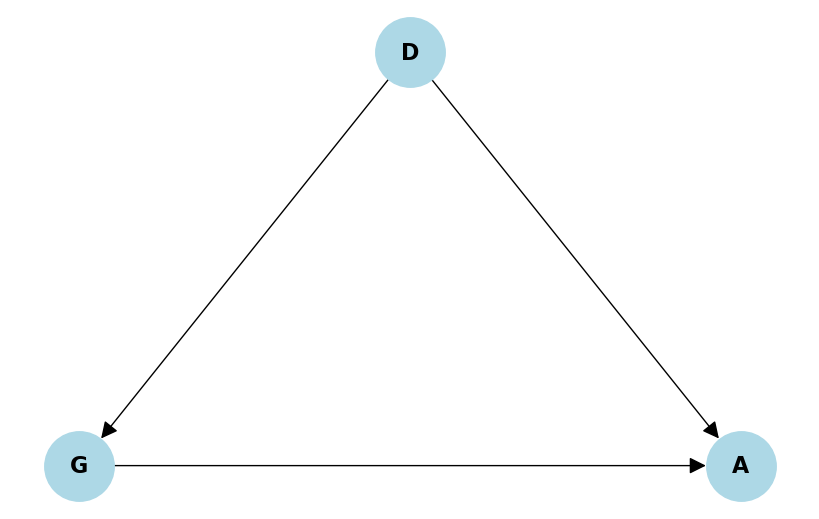

[('D', 'G'), ('D', 'A'), ('G', 'A')]


In [3]:



import networkx as nx
from matplotlib import pyplot as plt

graph = nx.DiGraph()

graph.add_edges_from([
    ("D", "G"),
    ("D", "A"),
    ("G", "A")
])

pos = {
    "D": (1, 2),
    "G": (0, 0),
    "A": (2, 0)
}

plt.figure(figsize=(8, 5))

nx.draw(
    graph,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2500,
    font_size=16,
    font_weight="bold",
    arrows=True,
    arrowsize=25
)

plt.tight_layout()
plt.show()

print(list(graph.edges()))


Describe what the nodes in your graph represent.

- **G (Gender):** The applicant's gender.
- **D (Discipline):** The research field the applicant applies to.
- **A (Awards):** Whether the applicant receives grant funding.

Next, define a Binomial GLM model that can be used to estimate the TOTAL causal effect of reported gender on grant awards. To begin, perform a prior predictive simulation.
- Define a prior distribution for an intercept-only model on the log-odds scale.
- Define the prior distribution such that the maximum value of its density is at 0.5 and the density decreases symmetrically as the values in the distribution get further from 0.5.
- Transform the samples from this prior distribution to the probability scale when plotting the samples.



/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


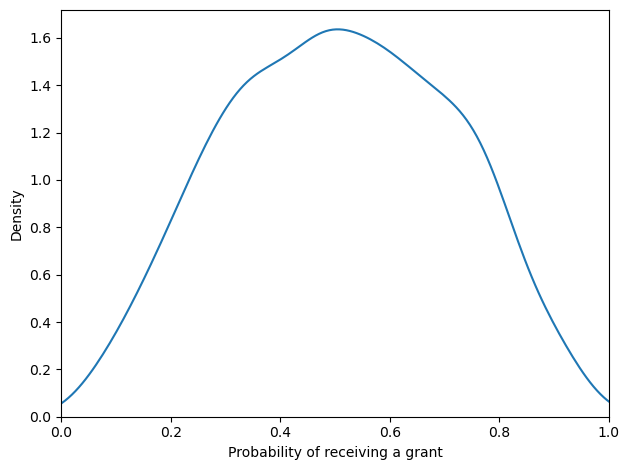

In [4]:

from scipy import stats
from scipy.special import expit
import seaborn as sns
import matplotlib.pyplot as plt

# Define number of prior samples
N_samples = 1000

# Sample from the prior on the log-odds scale
alpha = stats.norm.rvs(0, 1, size=N_samples)

# Convert log-odds to probabilities
p = expit(alpha)

# Plot prior predictive distribution
fig, ax = plt.subplots()

sns.kdeplot(x=p, ax=ax)

ax.set_xlabel("Probability of receiving a grant")
ax.set_ylabel("Density")
ax.set_xlim(0, 1)

# Store for autograder
q1_prior = ax

plt.tight_layout()
plt.show()


Provide justification for the prior distributions used in your model. **Limit your justification to no more than 5 sentences.**

**⚠️ PLEASE DO NOT DELETE THIS CELL**

I used a Normal(0, 1) prior for the intercept on the log-odds scale because it is centered at 0 and is symmetric. When converted to the probability scale, it gives the highest density around 0.5, with lower density as probabilities move further away. This prior allows for uncertainty while avoiding extremely high or low probabilities.

Process the dataset to be used in the models

In [5]:

import pandas as pd

# Read in data from Data/NWOGrants.csv
q1_df = pd.read_csv("Data/NWOGrants.csv", sep=";")

# Create an index variable for gender
q1_gender = pd.Categorical(q1_df["gender"]).codes

# Create variables for applications and awards
q1_applications = q1_df["applications"].to_numpy()
q1_awards = q1_df["awards"].to_numpy()

# Create a categorical variable for discipline
q1_discipline_as_category = q1_df["discipline"].astype("category")

# Store integer encoding of discipline categories
q1_discipline = q1_discipline_as_category.cat.codes.to_numpy()


In the cell below, implement the model that will be used to estimate the TOTAL causal effect of gender on award status. **Use the categorical index-based encoding approach demonstrated in lecture for including categorical variables in your model.**

In [6]:

import pymc as pm

# Define total causal effects model
with pm.Model() as q1_model:

    # Separate intercept for each gender
    alpha = pm.Normal(
        "alpha",
        mu=0,
        sigma=1,
        shape=len(np.unique(q1_gender))
    )

    # Convert log-odds to probabilities
    p = pm.Deterministic(
        "p",
        pm.math.invlogit(alpha[q1_gender])
    )

    # Binomial likelihood
    awards = pm.Binomial(
        "awards",
        n=q1_applications,
        p=p,
        observed=q1_awards
    )

    # Estimate posterior using HMC (NUTS)
    q1_idata = pm.sample(
        random_seed=rnd_seed,
        idata_kwargs={"log_likelihood": True}
    )


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [alpha]


<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:01&lt;00:00... Sampling chain 0, 0 divergences]</div>

<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:01&lt;00:00... Sampling chain 1, 0 divergences]</div>

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 3 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Using the code cell below, generate a gender contrast plot using `seaborn.kdeplot()`.

/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


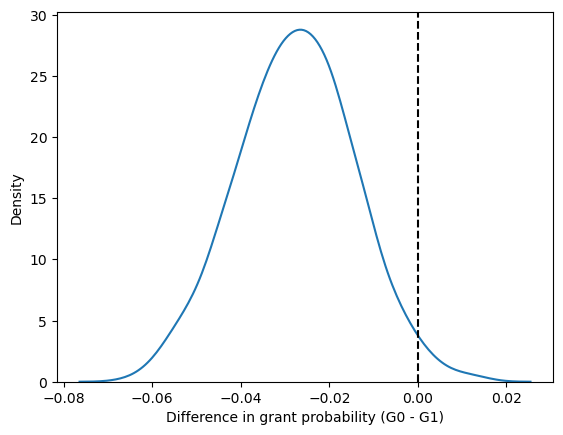

In [7]:

import arviz as az
import seaborn as sns
from scipy.special import expit as logistic
import matplotlib.pyplot as plt

# Extract 1000 posterior samples
q1_post = az.extract(q1_idata, num_samples=1000)

# Convert log-odds to probabilities
prob_A_G0 = logistic(q1_post.alpha.values[0, :])
prob_A_G1 = logistic(q1_post.alpha.values[1, :])

# Compute contrast
q1_diff_prob = prob_A_G0 - prob_A_G1

fig, ax = plt.subplots()

# Plot contrast distribution
sns.kdeplot(q1_diff_prob, ax=ax)

ax.axvline(0, linestyle="--", color="black")
ax.set_xlabel("Difference in grant probability (G0 - G1)")
ax.set_ylabel("Density")

# Store for autograder
q1_plot = ax

plt.show()


Provide a written interpretation of the plot. **Limit your interpretation of the plot to no more than 3 sentences.**

**⚠️ PLEASE DO NOT DELETE THIS CELL**
The plot shows that gender 0 (female) has a lower probability of receiving a grant than gender 1 (male). Most of the distribution is below zero, suggesting that male applicants have a higher overall grant approval rate. The difference is around 3 percentage points.

**Question 2**. Now construct a model that can be used to estimate the direct effect of reported gender on grant awards. Use this model to estimate the AVERAGE DIRECT causal effect of gender on grant awards using a counterfactual simulation as demonstrated in lecture.

**Notes** 
- _Refer to the counterfactual simulation for UC Berkeley admission outcomes from the lecture on Bernoulli/Binomial Generalized Linear Models for guidance. Its ok to just write code and generate plots for this question. Question 3 focuses on interpreting your results._
- Use the categorical index-based encoding approach demonstrated in lecture for including categorical variables in your model.

In [8]:


import pymc as pm
import numpy as np

with pm.Model() as q2_model:

    # Mutable data for counterfactual simulation
    gender_data = pm.Data("gender_data", q1_gender, mutable=True)
    discipline_data = pm.Data("discipline_data", q1_discipline, mutable=True)
    applications_data = pm.Data("applications_data", q1_applications, mutable=True)

    # Stratified intercept
    alpha = pm.Normal(
        "alpha",
        mu=0,
        sigma=1,
        shape=(
            len(np.unique(q1_gender)),
            len(np.unique(q1_discipline))
        )
    )

    # Probability of receiving a grant
    p = pm.Deterministic(
        "p",
        pm.math.invlogit(alpha[gender_data, discipline_data])
    )

    # Binomial likelihood
    awards = pm.Binomial(
        "awards",
        n=applications_data,
        p=p,
        observed=q1_awards,
        shape=applications_data.shape
    )

    # Posterior sampling
    q2_idata = pm.sample(
        random_seed=rnd_seed,
        idata_kwargs={"log_likelihood": True}
    )


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [alpha]


<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:02&lt;00:00... Sampling chain 0, 0 divergences]</div>

<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:02&lt;00:00... Sampling chain 1, 0 divergences]</div>

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 5 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Use samples from the posterior distribution to perform your counterfactual simulation. First, correctly define the following variables for setting up the counterfactual simulation.


In [9]:


import numpy as np
import pandas as pd

# Total number of applications
total_applications = int(q1_df["applications"].sum())

# Sum applications for each discipline (pandas Series)
applications_per_discipline = (
    q1_df.groupby("discipline")["applications"].sum()
)

# Create integer indices for disciplines
discipline_indices = np.arange(len(applications_per_discipline))

# Repeat each discipline index by application count
discipline_of_application = np.repeat(
    discipline_indices,
    applications_per_discipline.to_numpy()
)

# One Bernoulli trial per application
num_applications = np.ones(total_applications, dtype=int)

# Female applicants (0)
female_applicants = np.zeros(total_applications, dtype=int)

# Male applicants (1)
male_applicants = np.ones(total_applications, dtype=int)


Implement the female-only counterfactual simulation.


In [10]:


with q2_model:

    # Simulate all applications as female
    pm.set_data({
        "gender_data": female_applicants,
        "discipline_data": discipline_of_application,
        "applications_data": num_applications
    })

    # Sample posterior predictive distribution
    post_pred_female_idata = pm.sample_posterior_predictive(
        q2_idata,
        var_names=["awards"],
        random_seed=rnd_seed
    )

    # Extract posterior predictive samples
    counter_fact_female = az.extract(
        post_pred_female_idata,
        group="posterior_predictive",
        var_names=["awards"],
        keep_dataset=True
    )





Sampling: [awards]


<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:00&lt;00:00]</div>

Implement the male-only counterfactual simulation.


In [11]:

with q2_model:

    # Simulate as if all applications were from men
    pm.set_data({
        "gender_data": male_applicants,
        "discipline_data": discipline_of_application,
        "applications_data": num_applications
    })

    # Sample posterior predictive distribution
    post_pred_male_idata = pm.sample_posterior_predictive(
        q2_idata,
        var_names=["awards"],
        random_seed=rnd_seed
    )

    # Extract posterior predictive samples
    counter_fact_male = az.extract(
        post_pred_male_idata,
        group="posterior_predictive",
        var_names=["awards"],
        keep_dataset=True
    )



Sampling: [awards]


<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:00&lt;00:00]</div>

After estimating the average direct causal effect of gender on grant awards:
1. Plot the average direct causal effect as a contrast plot (using `seaborn.kdeplot()`) from the results of the counterfactual simulation.

/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


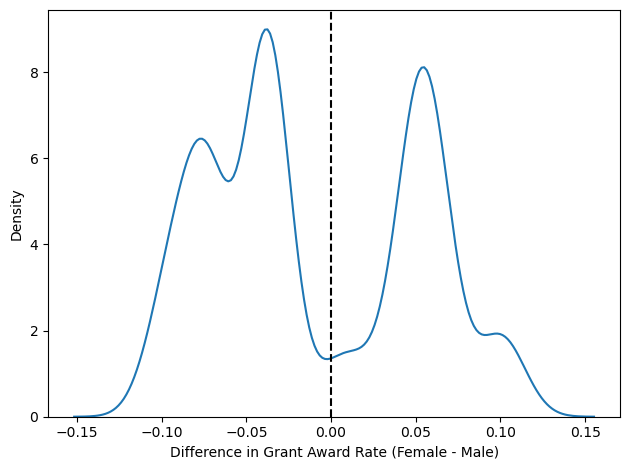

In [12]:


import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Compute award rate for each application
# Average across posterior samples
award_rate_female = counter_fact_female["awards"].mean(
    dim="sample"
).values

award_rate_male = counter_fact_male["awards"].mean(
    dim="sample"
).values

# Compute contrast (Female - Male)
q2_diff = award_rate_female - award_rate_male

fig, ax = plt.subplots()

# Plot contrast
sns.kdeplot(x=q2_diff, ax=ax)

ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Difference in Grant Award Rate (Female - Male)")
ax.set_ylabel("Density")

# Store Axes object for autograder
q2_plot = ax

plt.tight_layout()
plt.show()


2. Plot the DIRECT causal effect of reported gender by discipline, **weighting each discipline** in proportion to the number of applications in the observed data. *Refer to the lecture code for an example of how the thickness of the distribution curves can be determined in proportion to the number of applications.*

* **Add a legend** to your plot to label the discipline distributions. You can find documentation for adding a legend to your plot [here](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html). Specify a `label` each time you plot a contrast distribution and call the `matplotlib.pyplot.legend()` function before displaying the full plot to display the legend.

/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf va

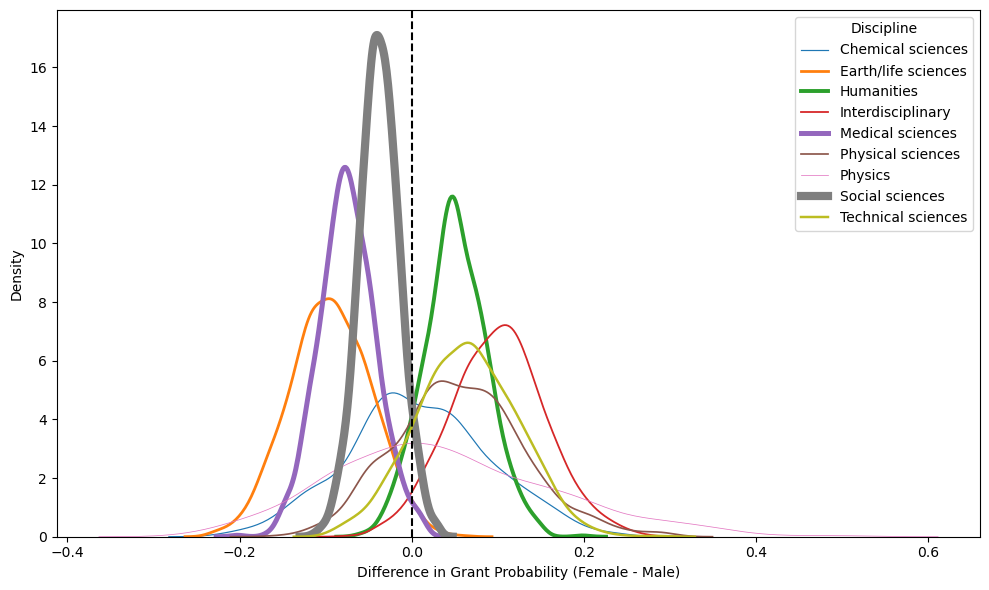

In [13]:



import arviz as az
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.special import expit as logistic

# Extract 1000 posterior samples
q2_post = az.extract(q2_idata, num_samples=1000)

# Convert log-odds to probabilities
q2_prob_alpha = logistic(q2_post.alpha.values)

# Number of disciplines
categories = q1_discipline_as_category.cat.categories
q2_num_disciplines = len(categories)

# Applications per discipline
discipline_counts = applications_per_discipline.reindex(categories)

fig, ax = plt.subplots(figsize=(10, 6))

# Store discipline contrast distributions
q2_contrasts = []

# Plot contrast distributions
for i in range(q2_num_disciplines):

    # Compute gender contrast for each discipline
    contrast = (
        q2_prob_alpha[0, i, :]
        - q2_prob_alpha[1, i, :]
    )

    # Weight line thickness by number of applications
    weight = discipline_counts.iloc[i] / total_applications
    line_width = weight * 20

    # Plot contrast distribution
    sns.kdeplot(
        x=contrast,
        ax=ax,
        label=categories[i],
        linewidth=line_width
    )

    # Store contrast
    q2_contrasts.append(contrast)

# Add x-axis label
plt.xlabel("Difference in Grant Probability (Female - Male)")

# Add vertical reference line at zero
plt.axvline(0, linestyle="--", color="black")

# Add legend
plt.legend(title="Discipline")

# Store Axes object for autograder
q2_plot_2 = ax

plt.tight_layout()
plt.show()
